Natural language processing: n-gram ranking
https://towardsdatascience.com/from-dataframe-to-n-grams-e34e29df3460

In [ ]:
!pip install -U deep-translator
import pandas as pd
from deep_translator import GoogleTranslator
from google.colab import drive
drive.mount('/content/drive')
# Dataset is now stored in a Pandas Dataframe
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/indeed_job_dataset_clean.csv')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 1.3 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
# natural language processing: n-gram ranking
#https://towardsdatascience.com/from-dataframe-to-n-grams-e34e29df3460
import re
import unicodedata
import nltk
from nltk.corpus import stopwords
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')

# add appropriate words that will be ignored in the analysis
ADDITIONAL_STOPWORDS = ['covfefe']

import matplotlib.pyplot as plt

def basic_clean(text):
  """
  A simple function to clean up the data. All the words that
  are not designated as a stop word is then lemmatized after
  encoding and basic regex parsing are performed.
  """
  wnl = nltk.stem.WordNetLemmatizer()
  stopwords = nltk.corpus.stopwords.words('english') + ADDITIONAL_STOPWORDS
  text = (unicodedata.normalize('NFKD', text)
    .encode('ascii', 'ignore')
    .decode('utf-8', 'ignore')
    .lower())
  words = re.sub(r'[^\w\s]', '', text).split()
  return [wnl.lemmatize(word) for word in words if word not in stopwords]

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
words = basic_clean(''.join(str(df['Description'].tolist())))

In [ ]:
# function that receives a n-grams series and translates each word to spanish using the GoogleTranslator library
def translate_series(serie):
  trad = []
  for i, val in serie.items():
    phrase = ""
    # translate each word separately for each phrase, so that the translator won't reinterpret them
    for j in i:
      phrase += GoogleTranslator(source='auto', target='es').translate(j) + ", "
    #remove last comma
    phrase=phrase.rstrip(", ")
    trad.append(phrase)

  serie.index = trad
  return serie

Text(0.5, 0, 'Número de ocurrencias')

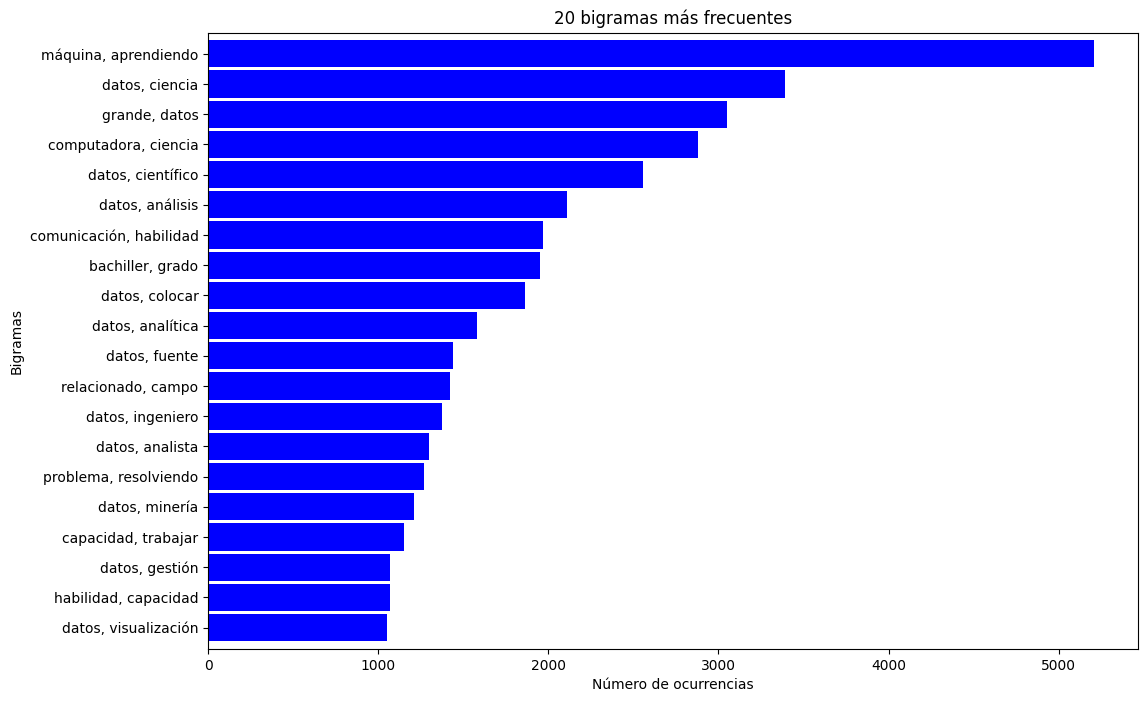

In [ ]:
ps_traducido = bigrams_series = translate_series((pd.Series(nltk.ngrams(words, 2)).value_counts())[:20])
ps_traducido.sort_values().plot.barh(color='blue', width=.9, figsize=(12, 8))
plt.title('20 bigramas más frecuentes')
plt.ylabel('Bigramas')
plt.xlabel('Número de ocurrencias')

In [ ]:
# Mean ocurrences
m2 = sum(bs for bs in ps_traducido)/len(ps_traducido)
m2

1945.3

Text(0.5, 0, 'Número de ocurrencias')

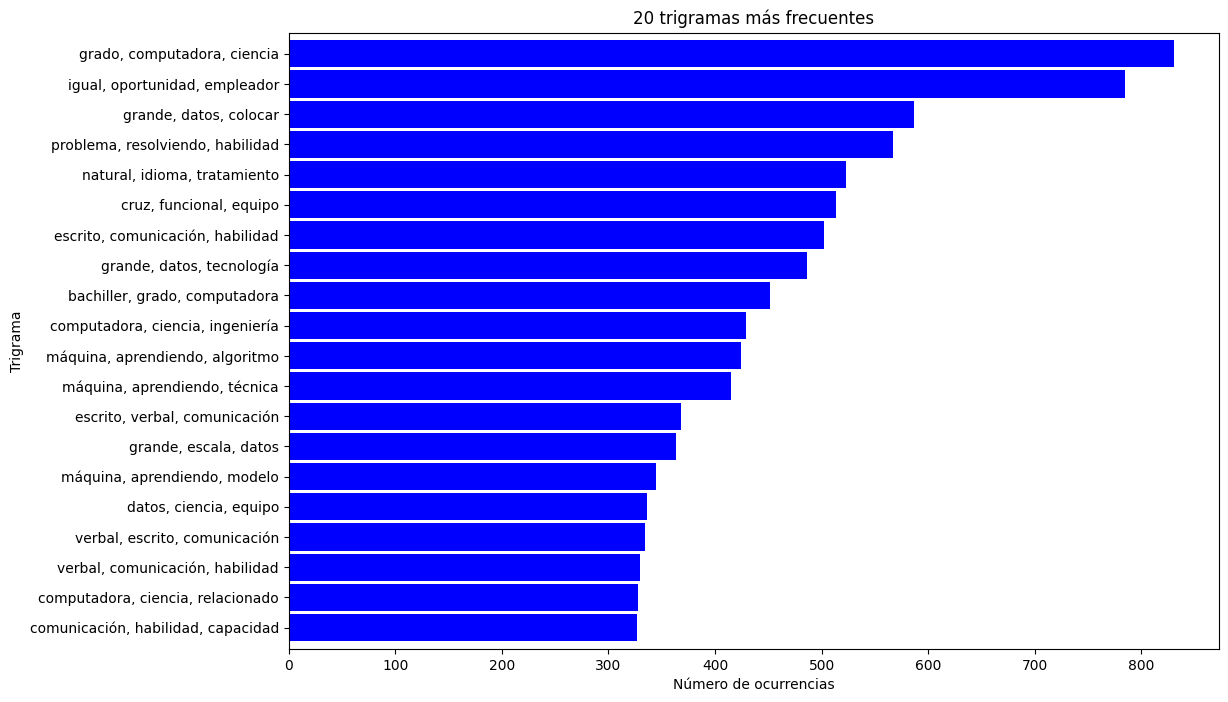

In [ ]:
ps_traducido = trigrams_series = translate_series((pd.Series(nltk.ngrams(words, 3)).value_counts())[:20])
ps_traducido.sort_values().plot.barh(color='blue', width=.9, figsize=(12, 8))
plt.title('20 trigramas más frecuentes')
plt.ylabel('Trigrama')
plt.xlabel('Número de ocurrencias')

In [ ]:
# Mean ocurrences
m3 = sum(int(bs) for bs in ps_traducido)/len(ps_traducido)
m3

462.3

Text(0.5, 0, 'Número de ocurrencias')

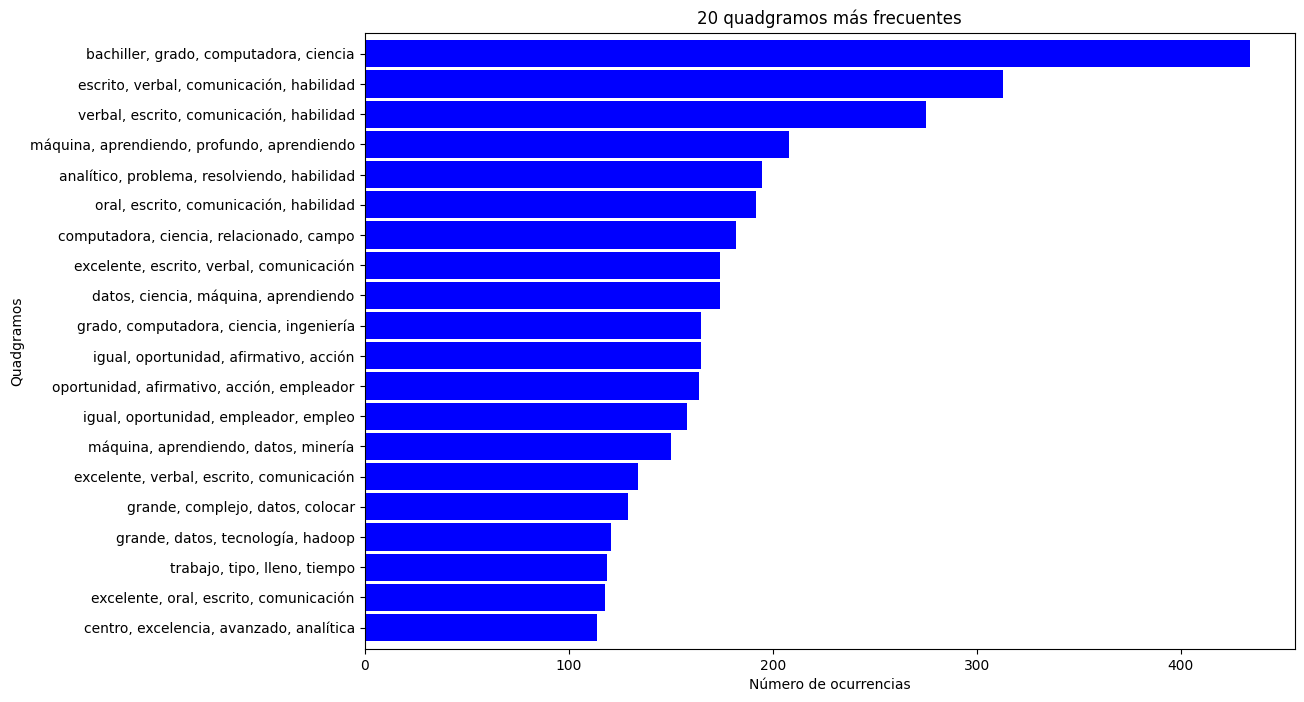

In [ ]:
ps_traducido = quad_series = translate_series((pd.Series(nltk.ngrams(words, 4)).value_counts())[:20])
ps_traducido.sort_values().plot.barh(color='blue', width=.9, figsize=(12, 8))
plt.title('20 quadgramos más frecuentes')
plt.ylabel('Quadgramos')
plt.xlabel('Número de ocurrencias')

In [ ]:
m4 = sum(int(bs) for bs in ps_traducido)/len(ps_traducido)
m4

184.2

Text(0.5, 0, 'Número de ocurrencias')

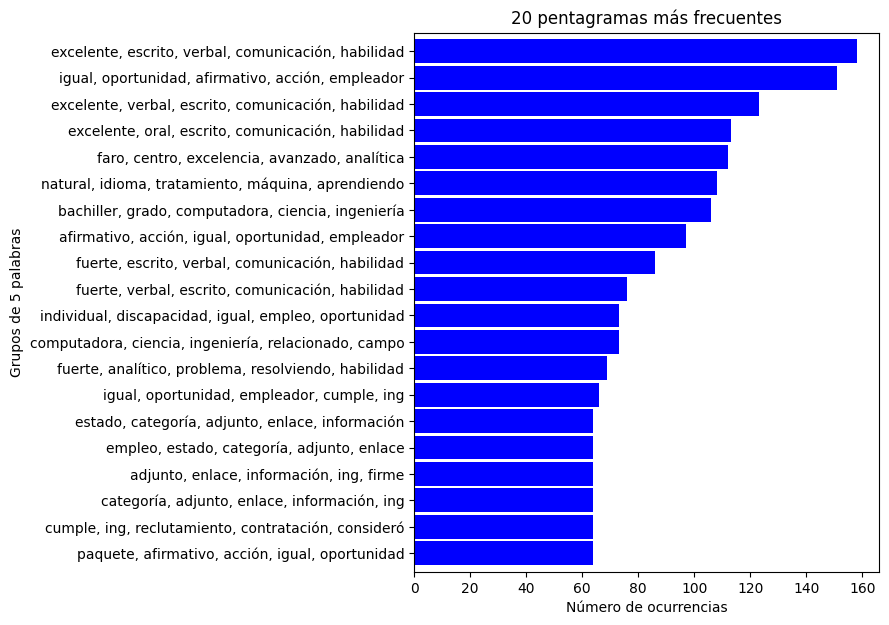

In [ ]:
ps_traducido = penta_series = translate_series((pd.Series(nltk.ngrams(words, 5)).value_counts())[:20])
ps_traducido.sort_values().plot.barh(color='blue', width=.9, figsize=(6, 7))
#plt.title('Frecuencia de ocurrencia de secuencia de 5 palabras')
plt.title('20 pentagramas más frecuentes')
plt.ylabel('Grupos de 5 palabras')
plt.xlabel('Número de ocurrencias')

In [ ]:
m5 = sum(int(bs) for bs in ps_traducido)/len(ps_traducido)
m5

89.75

In [ ]:
(pd.Series(nltk.ngrams(words, 5)).value_counts())[:20]

,count
"(excellent, written, verbal, communication, skill)",158
"(equal, opportunity, affirmative, action, employer)",151
"(excellent, verbal, written, communication, skill)",123
"(excellent, oral, written, communication, skill)",113
"(lighthouse, center, excellence, advanced, analytics)",112
"(natural, language, processing, machine, learning)",108
"(bachelor, degree, computer, science, engineering)",106
"(affirmative, action, equal, opportunity, employer)",97
"(strong, written, verbal, communication, skill)",86
"(strong, verbal, written, communication, skill)",76


In [ ]:
print(len(ps_traducido))

20


In [ ]:
print(ps_traducido)

excelente, escrito, verbal, comunicación, habilidad     158
igual, oportunidad, afirmativo, acción, empleador       151
excelente, verbal, escrito, comunicación, habilidad     123
excelente, oral, escrito, comunicación, habilidad       113
faro, centro, excelencia, avanzado, analítica           112
natural, idioma, tratamiento, máquina, aprendiendo      108
bachiller, grado, computadora, ciencia, ingeniería      106
afirmativo, acción, igual, oportunidad, empleador        97
fuerte, escrito, verbal, comunicación, habilidad         86
fuerte, verbal, escrito, comunicación, habilidad         76
individual, discapacidad, igual, empleo, oportunidad     73
computadora, ciencia, ingeniería, relacionado, campo     73
fuerte, analítico, problema, resolviendo, habilidad      69
igual, oportunidad, empleador, cumple, ing               66
cumple, ing, reclutamiento, contratación, consideró      64
paquete, afirmativo, acción, igual, oportunidad          64
adjunto, enlace, información, ing, firme

Text(0.5, 0, 'Número de ocurrencias')

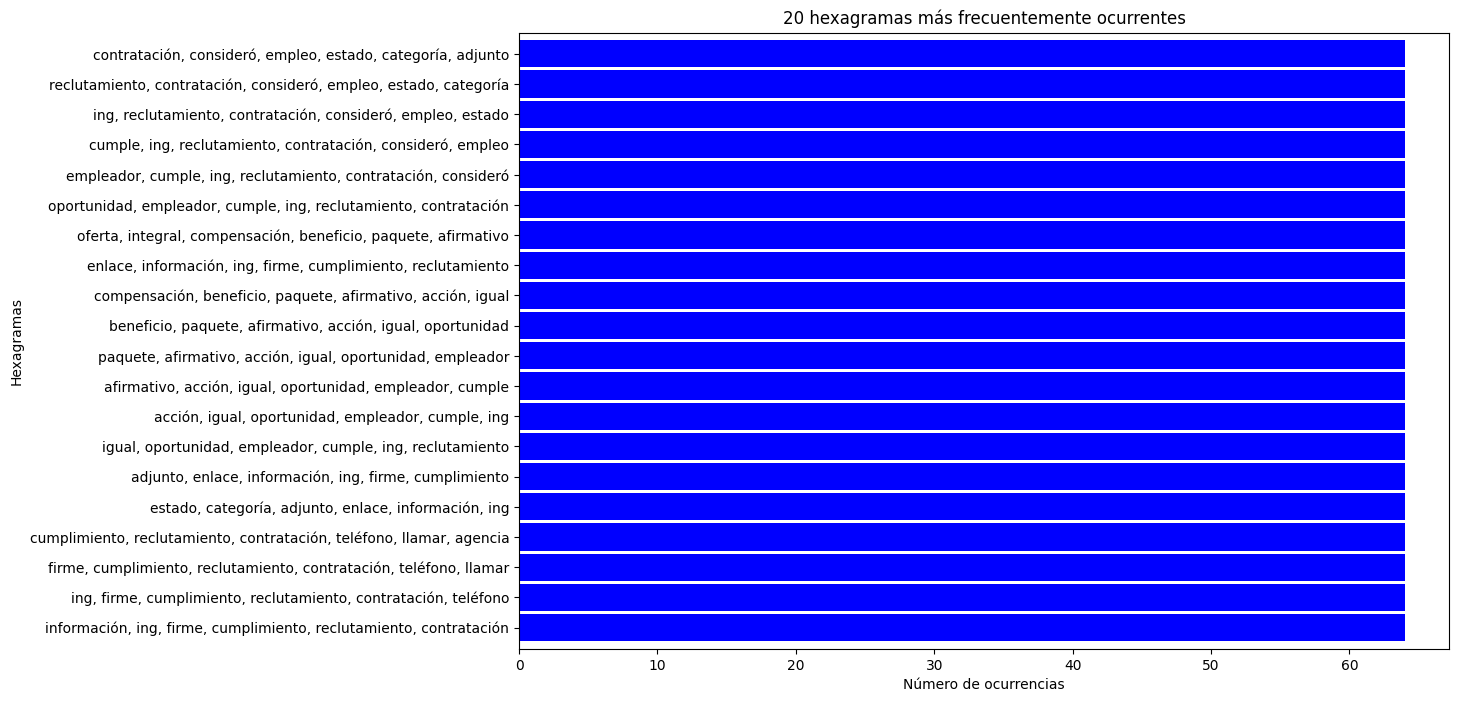

In [ ]:
ps_traducido = hexa_series = translate_series((pd.Series(nltk.ngrams(words, 6)).value_counts())[:20])
ps_traducido.sort_values().plot.barh(color='blue', width=.9, figsize=(12, 8))
plt.title('20 hexagramas más frecuentemente ocurrentes')
plt.ylabel('Hexagramas')
plt.xlabel('Número de ocurrencias')

In [ ]:
def uniques_count(ngram_series):
  #in a set() all items are unique
  words = set()
  for i, v in ngram_series.items():
    words_separated = i.split(", ")

    for word in words_separated:
      words.add(word)
  return len(words)

In [ ]:
u2 = uniques_count(bigrams_series)
u3 = uniques_count(trigrams_series)
u4 = uniques_count(quad_series)
u5 = uniques_count(penta_series)
u6 = uniques_count(hexa_series)

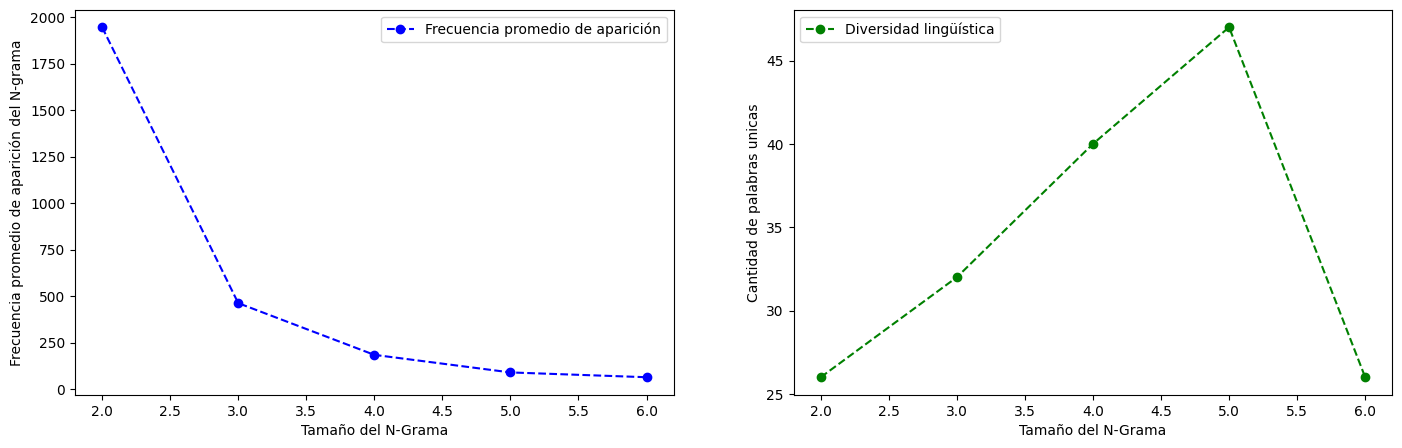

In [ ]:
figure, axis = plt.subplots(1, 2, figsize=(17, 5))
axis[0].plot((2,3,4,5,6),(m2,m3,m4,m5,m6), linestyle='--', marker='o', color='b', label='Frecuencia promedio de aparición')
axis[0].set_xlabel('Tamaño del N-Grama')
axis[0].set_ylabel('Frecuencia promedio de frases clave')
axis[0].legend()

axis[1].plot((2,3,4,5,6),(u2,u3,u4,u5,u6), linestyle='--', marker='o', color='g', label='Diversidad lingüística')
axis[1].set_xlabel('Tamaño del N-Grama')
axis[1].set_ylabel('Cantidad de palabras unicas')
axis[1].legend()

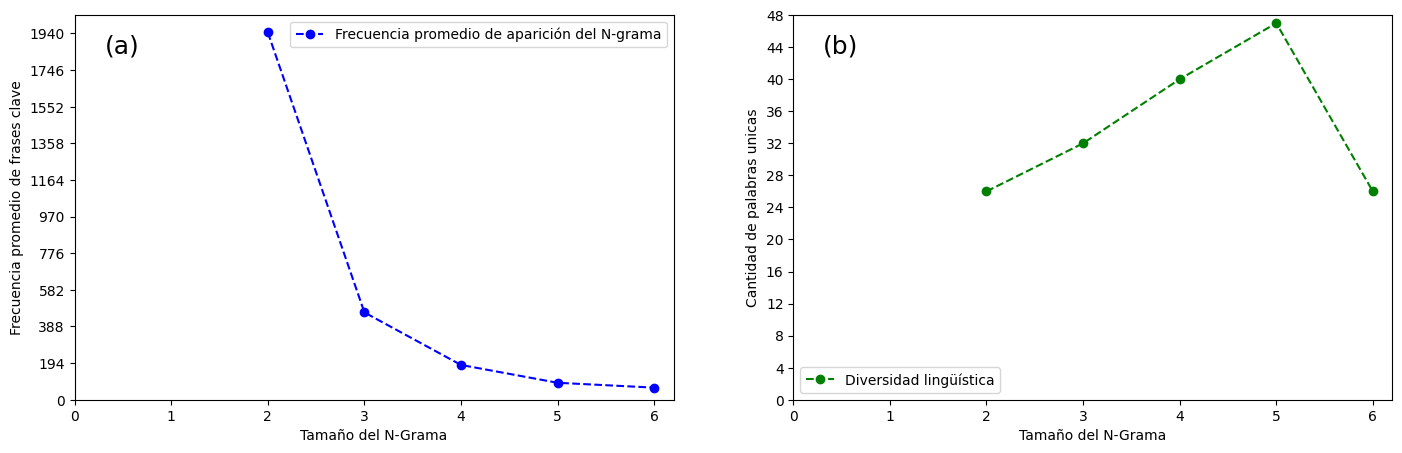

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

figure, axis = plt.subplots(1, 2, figsize=(17, 5))

# ---- Gráfico de Frecuencia media ----
axis[0].plot((2,3,4,5,6), (m2,m3,m4,m5,m6),
             linestyle='--', marker='o', color='b', label='Frecuencia promedio de aparición del N-grama')
axis[0].set_xlabel('Tamaño del N-Grama')
axis[0].set_ylabel('Frecuencia promedio de frases clave')
axis[0].legend()

# Forzar que arranquen en 0
axis[0].set_xlim(left=0)
axis[0].set_ylim(bottom=0)

# Ticks enteros dinámicos
ymax0 = max(m2,m3,m4,m5,m6)
step0 = max(1, ymax0 // 10)   # divide en ~10 ticks
axis[0].xaxis.set_major_locator(MultipleLocator(1))
axis[0].yaxis.set_major_locator(MultipleLocator(step0))
# Agregar etiqueta "a"
axis[0].text(0.05, 0.95, "(a)", transform=axis[0].transAxes,
             fontsize=18, fontweight="normal", va="top", ha="left")


# ---- Gráfico de Diversidad lingüística ----
axis[1].plot((2,3,4,5,6), (u2,u3,u4,u5,u6),
             linestyle='--', marker='o', color='g', label='Diversidad lingüística')
axis[1].set_xlabel('Tamaño del N-Grama')
axis[1].set_ylabel('Cantidad de palabras unicas')
axis[1].legend()

# Forzar que arranquen en 0
axis[1].set_xlim(left=0)
axis[1].set_ylim(bottom=0)

# Ticks enteros dinámicos
ymax1 = max(u2,u3,u4,u5,u6)
step1 = max(1, ymax1 // 10)
axis[1].xaxis.set_major_locator(MultipleLocator(1))
axis[1].yaxis.set_major_locator(MultipleLocator(step1))
# Agregar etiqueta "b"
axis[1].text(0.05, 0.95, "(b)", transform=axis[1].transAxes,
             fontsize=18, fontweight="normal", va="top", ha="left")

plt.show()


In [ ]:
phrases_set = set()
time_set = set()
import time
# Importing the library for RAM usage
import psutil

for counter in range(10):

  start_time = time.time()

  penta_series = pd.Series(nltk.ngrams(words, 5)).value_counts()
  print(penta_series)
  execution_time_seconds = round((time.time() - start_time), 2)
  print("--- %s seconds ---" % execution_time_seconds)
  time_set.add(execution_time_seconds)
  #print(penta_series[:20])

  results = pd.DataFrame(penta_series).index
  for i in results:
    joini = " ".join(i)
    phrases_set.add(joini)

  # Getting % usage of virtual_memory ( 3rd field)
  print('RAM memory % used:', psutil.virtual_memory()[2])
  # Getting usage of virtual_memory in GB ( 4th field)
  print('RAM Used (GB):', psutil.virtual_memory()[3]/1000000000)

(excellent, written, verbal, communication, skill)       158
(equal, opportunity, affirmative, action, employer)      151
(excellent, verbal, written, communication, skill)       123
(excellent, oral, written, communication, skill)         113
(lighthouse, center, excellence, advanced, analytics)    112
                                                        ... 
(macro, economic, condition, motif, capital)               1
(economic, condition, motif, capital, modernizing)         1
(condition, motif, capital, modernizing, fundamental)      1
(money, invested, portfolio, advisor, job)                 1
(priority, assignment, insight, drawn, research)           1
Name: count, Length: 838794, dtype: int64
--- 3.11 seconds ---
RAM memory % used: 15.7
RAM Used (GB): 1.804890112
(excellent, written, verbal, communication, skill)       158
(equal, opportunity, affirmative, action, employer)      151
(excellent, verbal, written, communication, skill)       123
(excellent, oral, written, commu

In [ ]:
import statistics
statistics.mean(time_set)

2.979